In [1]:
import os
import platform
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt
from astropy import units as u
from astropy import constants as ct

import belfast.mcmc_utils as mcmc
from belfast.plot_utils import create_interp_func_PARS
from belfast.target_utils import query_data, add_extinction
from belfast.target_definition import Target
from belfast.isochrone_utils import load_default_regularized_PARSECv2_Mini_interpolator, load_default_regularized_PARSECv2_u_interpolator

# Prepare data


## Option 1: Reproduce the mock-star result presented in the paper

In [2]:
target_name      = 'paper mock star'
cluster          = 'None'

true_values      = np.array([2.05, 180, 0.01, 0.8, 0.524, 10])
bands_list       = ['G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks']
obs_err_mags     = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
vsini_obs_err    = 5
parallax_obs     = true_values[5]
parallax_obs_err = 0.03
extinction       = 0.01
extinction_err   = 0.01
extinction_type  = 'A_V'
vsini_obs        = 110
obs_mags         = np.array([6.508, 6.512, 6.482, 6.59,  6.533, 6.421, 6.482, 6.449])

## Option 2: Test user-defined stellar parameters
You can run a test using mock data generated from PARSEC v2.0 isochrones.

In [3]:
# select a way to load interpolation models

# grids_type = "with_inc"         # using much memory (~32 GB)
grids_type = "without_inc"    # using less memory (~2 GB)


interp_func_Mini, *_ = load_default_regularized_PARSECv2_Mini_interpolator(grid_type=grids_type, label_list=[0, 1])
interp_func_u, interp_u, *_ = load_default_regularized_PARSECv2_u_interpolator(grid_type=grids_type, label_list=[0, 1])

if grids_type == "without_inc":
    interp_func_Mini_PARS = create_interp_func_PARS(
        interp_func=interp_func_Mini,
        PARS_nz=100,
        PARS_MH_offset=-0.046,
        show_progress=True,
    )
    interp_func_u_PARS = create_interp_func_PARS(
        interp_func=interp_func_u,
        PARS_nz=100,
        PARS_MH_offset=-0.046,
        show_progress=True,
    )

Age_grid: [1.0, 2001.01341407] Myr
Age_grid shape: (219,)
Loaded regularized Mini grid using ndimage.map_coordinates.
grid_type: without_inc
label_list: [0, 1]
interp_variable_list: ['Mini', 'Age', 'MH', 'omega_ini']
interp_output_list: ['Mass', 'omega', 'logL', 'logTe', 'Req', 'Rpol']
grid_outputs shape: (1392, 219, 13, 7, 6)
grid_bounds shape: (219, 13, 7, 2)
grid_outputs dtype: float32
grid_bounds dtype: float32
save_float32: True
read_all_at_once: True
total grid memory: 635.11 MB (0.62 GB)
Axis spacing:
  Mini           : uniform
  Age            : non-uniform
  MH             : non-uniform
  omega_ini      : non-uniform
Loaded u-regularized grid.
grid_type: without_inc
label_list: [0, 1]
interp_variable_list: ['Mini', 'Age', 'MH', 'omega_ini']
interp_variable_list_regular: ['u', 'Age', 'MH', 'omega_ini']
interp_output_list: ['Mass', 'omega', 'logL', 'logTe', 'Req', 'Rpol']
u_grid shape: (1392,)
grid_outputs shape: (1392, 219, 13, 7, 6)
grid_bounds shape: (219, 13, 7, 2)
grid_outp

100%|██████████| 18/18 [01:39<00:00,  5.54s/it]


In [4]:
np.random.seed(42)

target_name      = 'mock star'
cluster          = 'None'

true_values      = np.array([2.05, 180, 0.01, 0.8, 0.524, 10])
bands_list       = ['G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks']
obs_err_mags     = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
vsini_obs_err    = 5
parallax_obs     = true_values[5]
parallax_obs_err = 0.03
extinction       = 0.01
extinction_err   = 0.01
extinction_type  = 'A_V'

if grids_type == "with_inc":
    u = interp_u(true_values[:-1])
    if u < 0.8:
        interp_func = interp_func_Mini
    else:
        interp_func = interp_func_u

elif grids_type == "without_inc":
    u = interp_u(true_values[:-2])
    if u < 0.8:
        interp_func = interp_func_Mini_PARS
    else:
        interp_func = interp_func_u_PARS
else:
    raise ValueError("'grids_type' must be 'with_inc' or 'without_inc'")

obs_mags_model      = interp_func(true_values[:-1])[-8:] + np.log10(1000/parallax_obs) * 2.5
obs_mags_model_err  = np.zeros_like(obs_mags_model)

Mass, omega, _, _, Req, Rpol = interp_func(true_values[:-1])[:-8]
vsini_obs = (np.sqrt(Mass * ct.GM_sun / (Rpol * 1.5 * ct.R_sun)**3) * omega * Req * ct.R_sun.to('km') * np.sin(true_values[4])).value

# adding interstellar extinction
obs_mags_add_extinction = add_extinction(obs_mags_model, obs_mags_model_err, bands_list, extinction, extinction_err, extinction_type, verbose=False)[0]
# inserting Gaussian noise
obs_mags = np.round(obs_mags_add_extinction + np.random.normal(loc=0.0, scale=[0.02]*8), 3)

print(f'u = {u}')
print('vsini=', vsini_obs, 'km/s')
print('obs_mags=', obs_mags)

u = 0.46392921941803655
vsini= 110.34838577442024 km/s
obs_mags= [6.51  6.512 6.487 6.583 6.498 6.447 6.477 6.453]


# Set Target

In [5]:
target = Target(
    name = target_name,
    bands_list = ['G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks'],
    obs_mags = obs_mags,
    obs_err_mags = obs_err_mags,
    vsini_obs = vsini_obs,
    vsini_obs_err = vsini_obs_err,
    parallax_obs = parallax_obs,
    parallax_obs_err = parallax_obs_err,
    sigma_adjustment_parameter = 1,
    extinction_parameter = True,
)

In [6]:
# sample all parameters
target.add_info(
    cluster=cluster,
    sampling_variables_list = ['Mini', 'Age', 'MH', 'omega_ini', 'Inclination', 'parallax'],
    extinction=extinction,
    extinction_err=extinction_err,
    extinction_type=extinction_type,
)

target.known_parameter(true_values=true_values) # for mock stars, you may set the true values and overplot them on corner plots

In [ ]:
# # if you want to sample with fixed metallicity [M/H] = 0.0, please give the value by target.known_parameter()
# target.add_info(
#     cluster=cluster,
#     sampling_variables_list = ['Mini', 'Age', 'omega_ini', 'Inclination', 'parallax'], # not sampling MH
#     extinction=extinction,
#     extinction_err=extinction_err,
#     extinction_type=extinction_type,
# )
#
# target.known_parameter(known_MH=0) # giving fixed MH here

In [ ]:
# # If assuming non-rotation
# target.add_info(
#     cluster=cluster,
#     sampling_variables_list = ['Mini', 'Age', 'MH', 'parallax'], # not sampling omega_ini and inclination
#     extinction=extinction,
#     extinction_err=extinction_err,
#     extinction_type=extinction_type,
# )
#
# target.known_parameter(known_omega_ini=1e-8, known_Inclination=1e-8) # giving fixed omega_ini and Inclination here

# Set method

In [ ]:
# # Standard Regularization + METHOD DIRECT   (~16 GB memory is needed.)
#
# target.set_method(
#     regrid_type='Mini',
#     label_list=[0, 1],
#     METHOD='DIRECT',
# )

In [7]:
# # Standard Regularization + METHOD PARS   (~1 GB memory is needed.)

target.set_method(
    regrid_type='Mini',
    label_list=[0, 1],
    METHOD='PARS',
)

****************************************************************************************************
Using PARSEC isochrones with Mini grids and PARS method.
****************************************************************************************************
Age_grid: [1.0, 2001.01341407] Myr
Age_grid shape: (219,)
Loaded regularized Mini grid using ndimage.map_coordinates.
grid_type: without_inc
label_list: [0, 1]
interp_variable_list: ['Mini', 'Age', 'MH', 'omega_ini']
interp_output_list: ['Mass', 'omega', 'logL', 'logTe', 'Req', 'Rpol']
grid_outputs shape: (1392, 219, 13, 7, 6)
grid_bounds shape: (219, 13, 7, 2)
grid_outputs dtype: float32
grid_bounds dtype: float32
save_float32: True
read_all_at_once: True
total grid memory: 635.11 MB (0.62 GB)
Axis spacing:
  Mini           : uniform
  Age            : non-uniform
  MH             : non-uniform
  omega_ini      : non-uniform
Loading limb darkening files from Kurucz's model.


100%|██████████| 11/11 [01:02<00:00,  5.71s/it]


In [ ]:
# # Reparameterized Regularization + METHOD DIRECT    (~16 GB memory is needed.)
#
# target.set_method(
#     regrid_type='u',
#     label_list=[0, 1],
#     METHOD='DIRECT',
# )

In [ ]:
# # Reparameterized Regularization + METHOD PARS   (~1 GB memory is needed.)
#
# target.set_method(
#     regrid_type='u',
#     label_list=[0, 1],
#     METHOD='PARS',
# )

In [ ]:
# # MIST isochrones + METHOD PARS   (~1 GB memory is needed.)
#
# target.set_method(
#     regrid_type='Mini',
#     iso_name='MIST',
#     METHOD='PARS',
# )

# Sampling

In [8]:
# Set initial states and prior distributions for sampling.

target.set_sampling(
    n_walkers=30,
    MH_prior = lambda x: norm.logpdf(x, loc=true_values[2], scale=0.05),
    inclination_prior = lambda x: norm.logpdf(x, loc=true_values[4], scale=np.deg2rad(6)),
    extinction_prior = lambda x: norm.logpdf(x, loc=extinction, scale=extinction_err),
)

Sampling parameter space:
Parameter           Min        Max
----------------------------------
Mini             0.0900    14.0000
Age              1.0000  2001.0134
MH              -2.1917     0.3363
omega_ini        0.0000     0.9900
Inclination      0.0000     1.5708
parallax         5.0000    15.0000
extinction       0.0000     1.0000
sigma            0.0000     0.1000


Estimating rough mass...


100%|██████████| 3000/3000 [01:04<00:00, 46.29it/s]


acceptance ratio:
	0.22 0.24 0.24 0.23 0.24 0.22 0.23 0.23 0.22 
	0.23 0.23 0.22 0.21 0.22 0.24 0.22 0.24 0.21 
	0.24 0.24 0.26 0.23 0.24 0.25 0.22 0.20 0.21 
	0.20 0.21 0.22 
mean acceptance ratio: 0.227
n_steps/60: 50.00
autocorrelation time: [190 289 282 332 301 188 237 259]


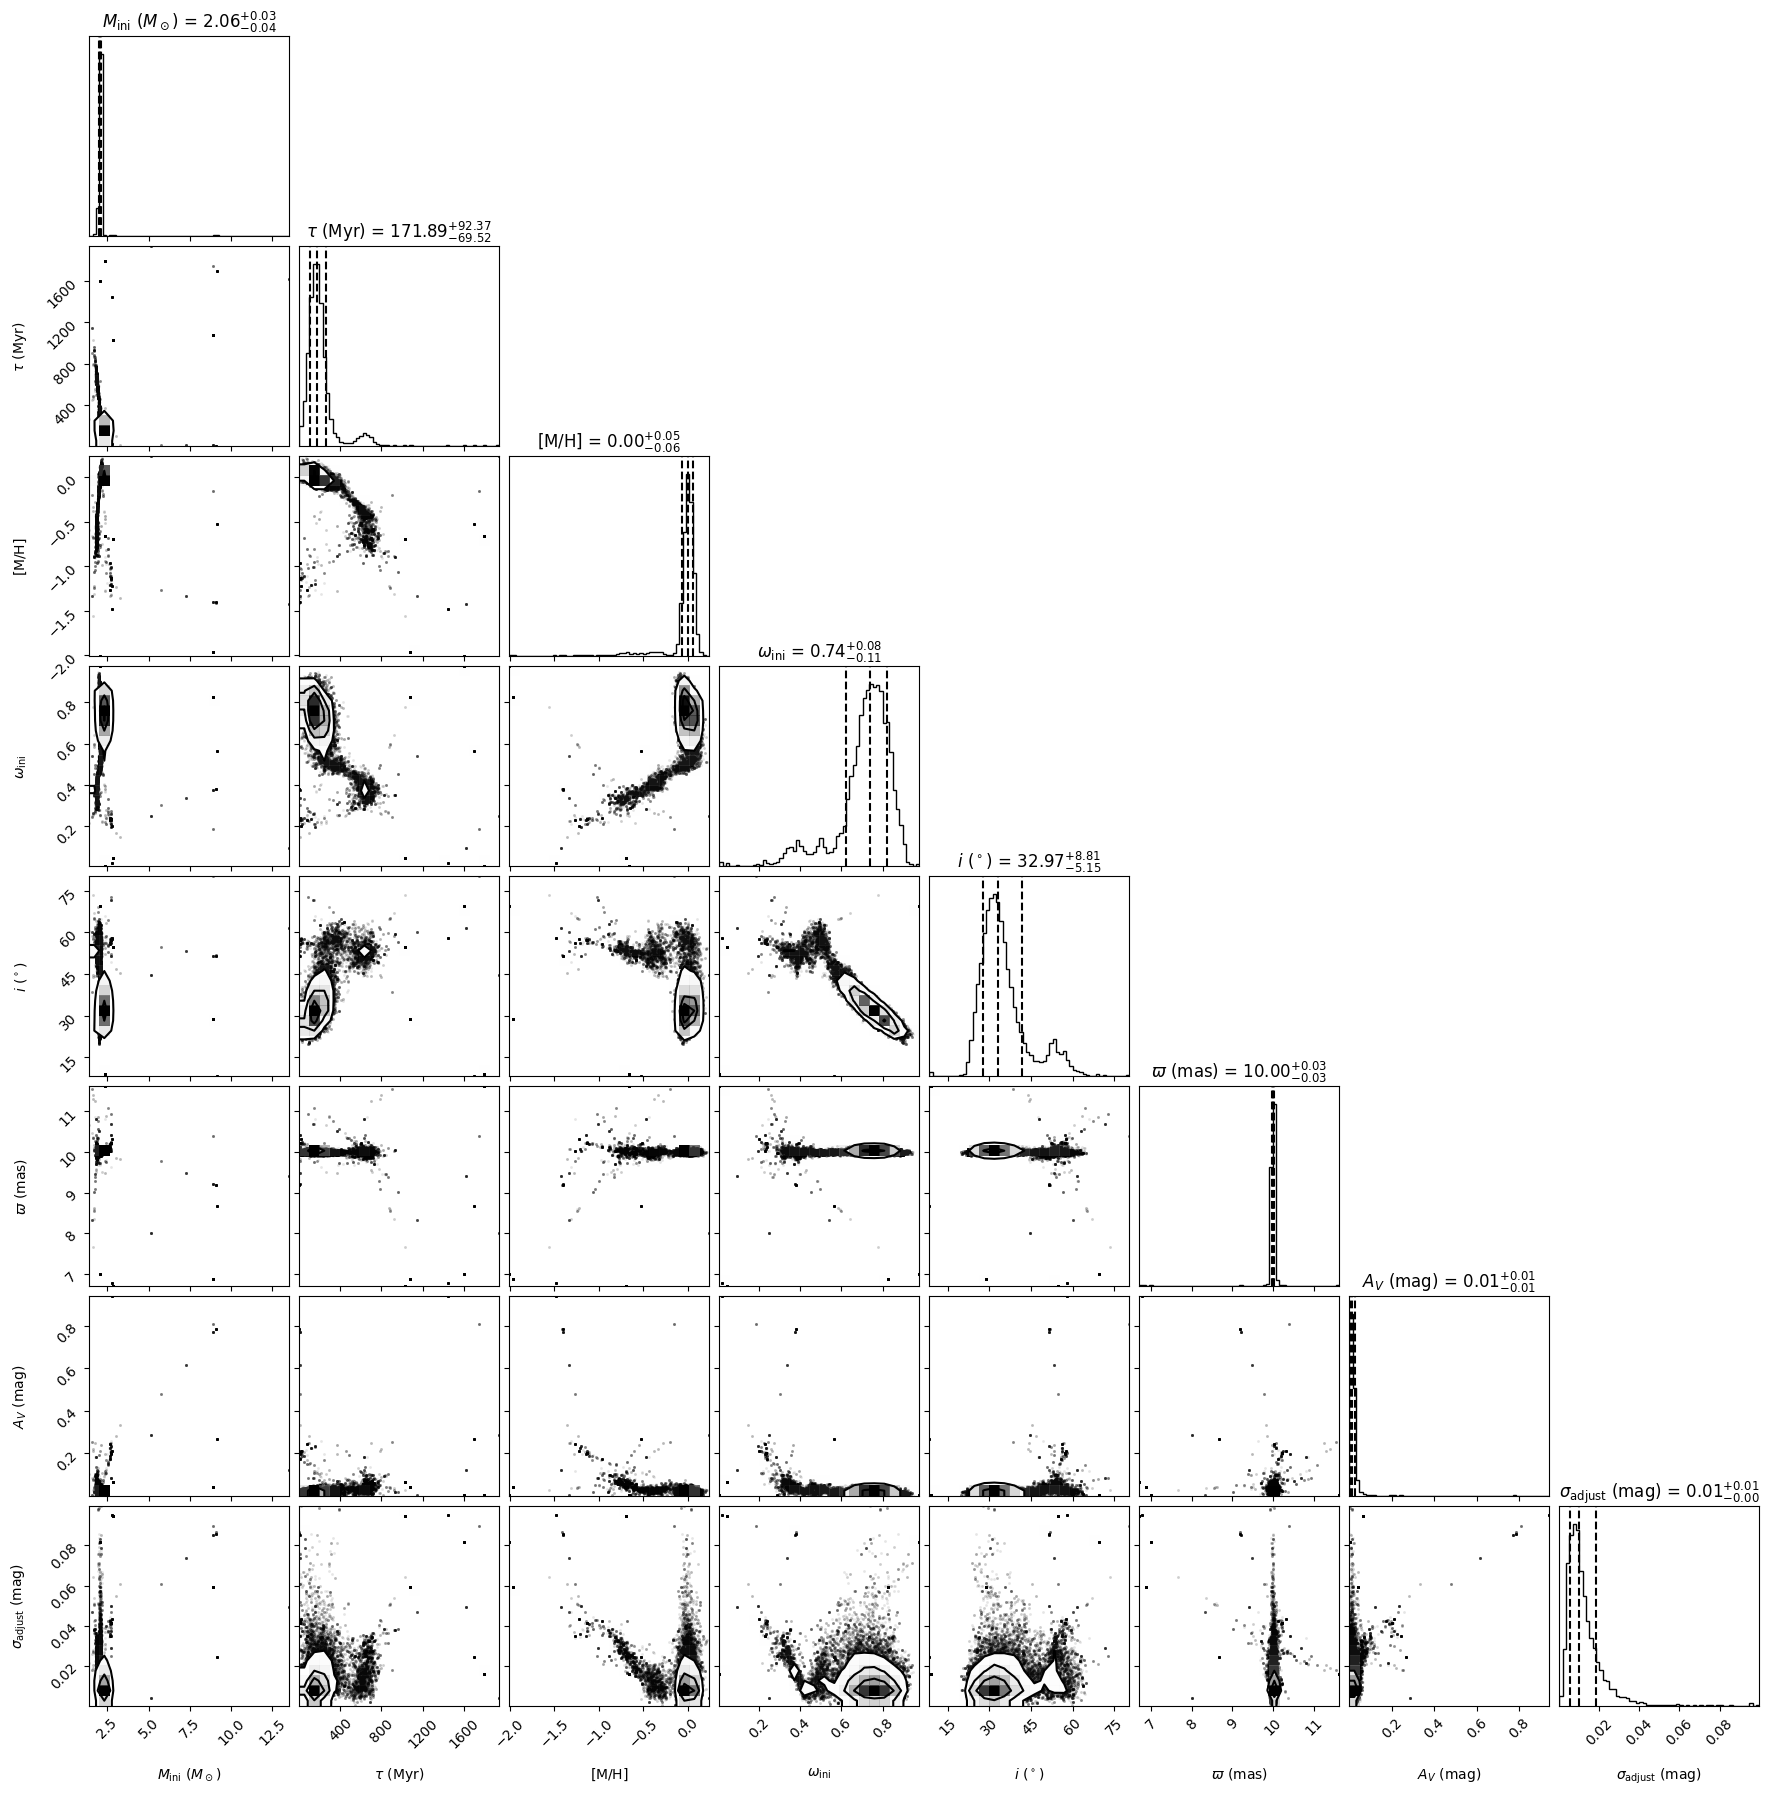

In [9]:
# quick-look tests

mcmc.target = target
sampler_test, target = mcmc.run_test_sampling(
    n_steps_test=3000,
    n_processes=8,
    save_samples=False,
)

In [10]:
# Run sampling!
# Set max time for running and processes for parallel

mcmc.target = target
sampler = mcmc.run_sampling(
    initial_steps = 10000,  # the interval for checking convergence (e.g. 10000, 30000, 60000)
    max_hours=3,            # hours; if reaching max_hours, stop sampling anyway.
    n_processes=8,          # the number of threads used for parallel sampling.
)

# Play sounds to indicate completion (macOS only).
if platform.system() == "Darwin":
    for _ in range(3):
        os.system("afplay /System/Library/Sounds/Glass.aiff")

🔄 Initial sampling: 10000 steps


 42%|████▏     | 4246/10000 [01:33<02:06, 45.49it/s]/Users/ziyinggu/Programming/GitHub/paint_atmospheres/pa/lib/surface.py:175: RuntimeWarning: divide by zero encountered in divide
  return numerator / denominator
/Users/ziyinggu/Programming/GitHub/paint_atmospheres/pa/lib/surface.py:194: RuntimeWarning: invalid value encountered in divide
  b[m] = - self.cosi * drz / sqt
100%|██████████| 10000/10000 [03:43<00:00, 44.68it/s]


🚀 Standard criteria: usable N/τ ≥ 70, τ_diff < 20%

🔍 Checkpoint @ 10000 steps (elapsed 0h 3m)
  τ₀․₅=132.9, τ₀․₃=111.2, τ_diff=16.3%
  Usable N/τ after burn=10τ: 65.2 / 70
⏱ Next: 1330 steps (missing 4.8τ, planned 10.0τ)


 52%|█████▏    | 689/1330 [00:15<00:14, 44.49it/s]/Users/ziyinggu/Programming/GitHub/paint_atmospheres/pa/lib/surface.py:175: RuntimeWarning: divide by zero encountered in divide
  return numerator / denominator
/Users/ziyinggu/Programming/GitHub/paint_atmospheres/pa/lib/surface.py:194: RuntimeWarning: invalid value encountered in divide
  b[m] = - self.cosi * drz / sqt
100%|██████████| 1330/1330 [00:29<00:00, 44.72it/s]



🔍 Checkpoint @ 11330 steps (elapsed 0h 4m)
  τ₀․₅=140.0, τ₀․₃=122.9, τ_diff=12.2%
  Usable N/τ after burn=10τ: 70.9 / 70
⏱ Next: 1401 steps (missing 0.0τ, planned 10.0τ)


100%|██████████| 1401/1401 [00:32<00:00, 42.64it/s]


... (3 outputs left out)

100%|██████████| 1924/1924 [01:08<00:00, 27.92it/s]



🔍 Checkpoint @ 16272 steps (elapsed 0h 6m)
  τ₀․₅=187.2, τ₀․₃=159.1, τ_diff=15.0%
  Usable N/τ after burn=10τ: 76.9 / 70
⏱ Next: 1872 steps (missing 0.0τ, planned 10.0τ)


 80%|████████  | 1498/1872 [01:06<00:14, 26.29it/s]/Users/ziyinggu/Programming/GitHub/paint_atmospheres/pa/lib/map.py:109: RuntimeWarning: divide by zero encountered in power
  geff = np.sqrt( rho**-4 + omega**4 * r_sq - 2 * omega**2 * r_sq * rho**-3 )
/Users/ziyinggu/Programming/GitHub/paint_atmospheres/pa/lib/map.py:109: RuntimeWarning: invalid value encountered in multiply
  geff = np.sqrt( rho**-4 + omega**4 * r_sq - 2 * omega**2 * r_sq * rho**-3 )
/Users/ziyinggu/Programming/GitHub/paint_atmospheres/pa/lib/map.py:169: RuntimeWarning: invalid value encountered in divide
  x_arr = np.abs(z_arr / (surf.f * rho_arr))
100%|██████████| 1872/1872 [01:23<00:00, 22.48it/s]



🔍 Checkpoint @ 18144 steps (elapsed 0h 7m)
  τ₀․₅=185.3, τ₀․₃=153.4, τ_diff=17.2%
  Usable N/τ after burn=10τ: 87.9 / 70
✅ Converged: τ stable for 2 checkpoints and usable N/τ ≥ 70
Total sampling time: 00:07:55
Total MCMC steps of each walker: 18144


📏 τ₀․₅=185.3, τ₀․₃=153.4, τ_late=185.3 → burn-in=1852
Results and plots will be saved at
	/Users/ziyinggu/Programming/GitHub/BELFAST/results/mock_star_None_PARSEC_PARS_Mini_grid_A_V_sigma1_A_V_prior_0.01±0.01;_MH_prior_0.01±0.05;_inc_prior_30±6_2
True values: [2.05, 180.0, 0.01, 0.8, 0.524, 10.0, 0.01, 0]
==> Overplot true values on the original corner plot.
Finished saving plots.


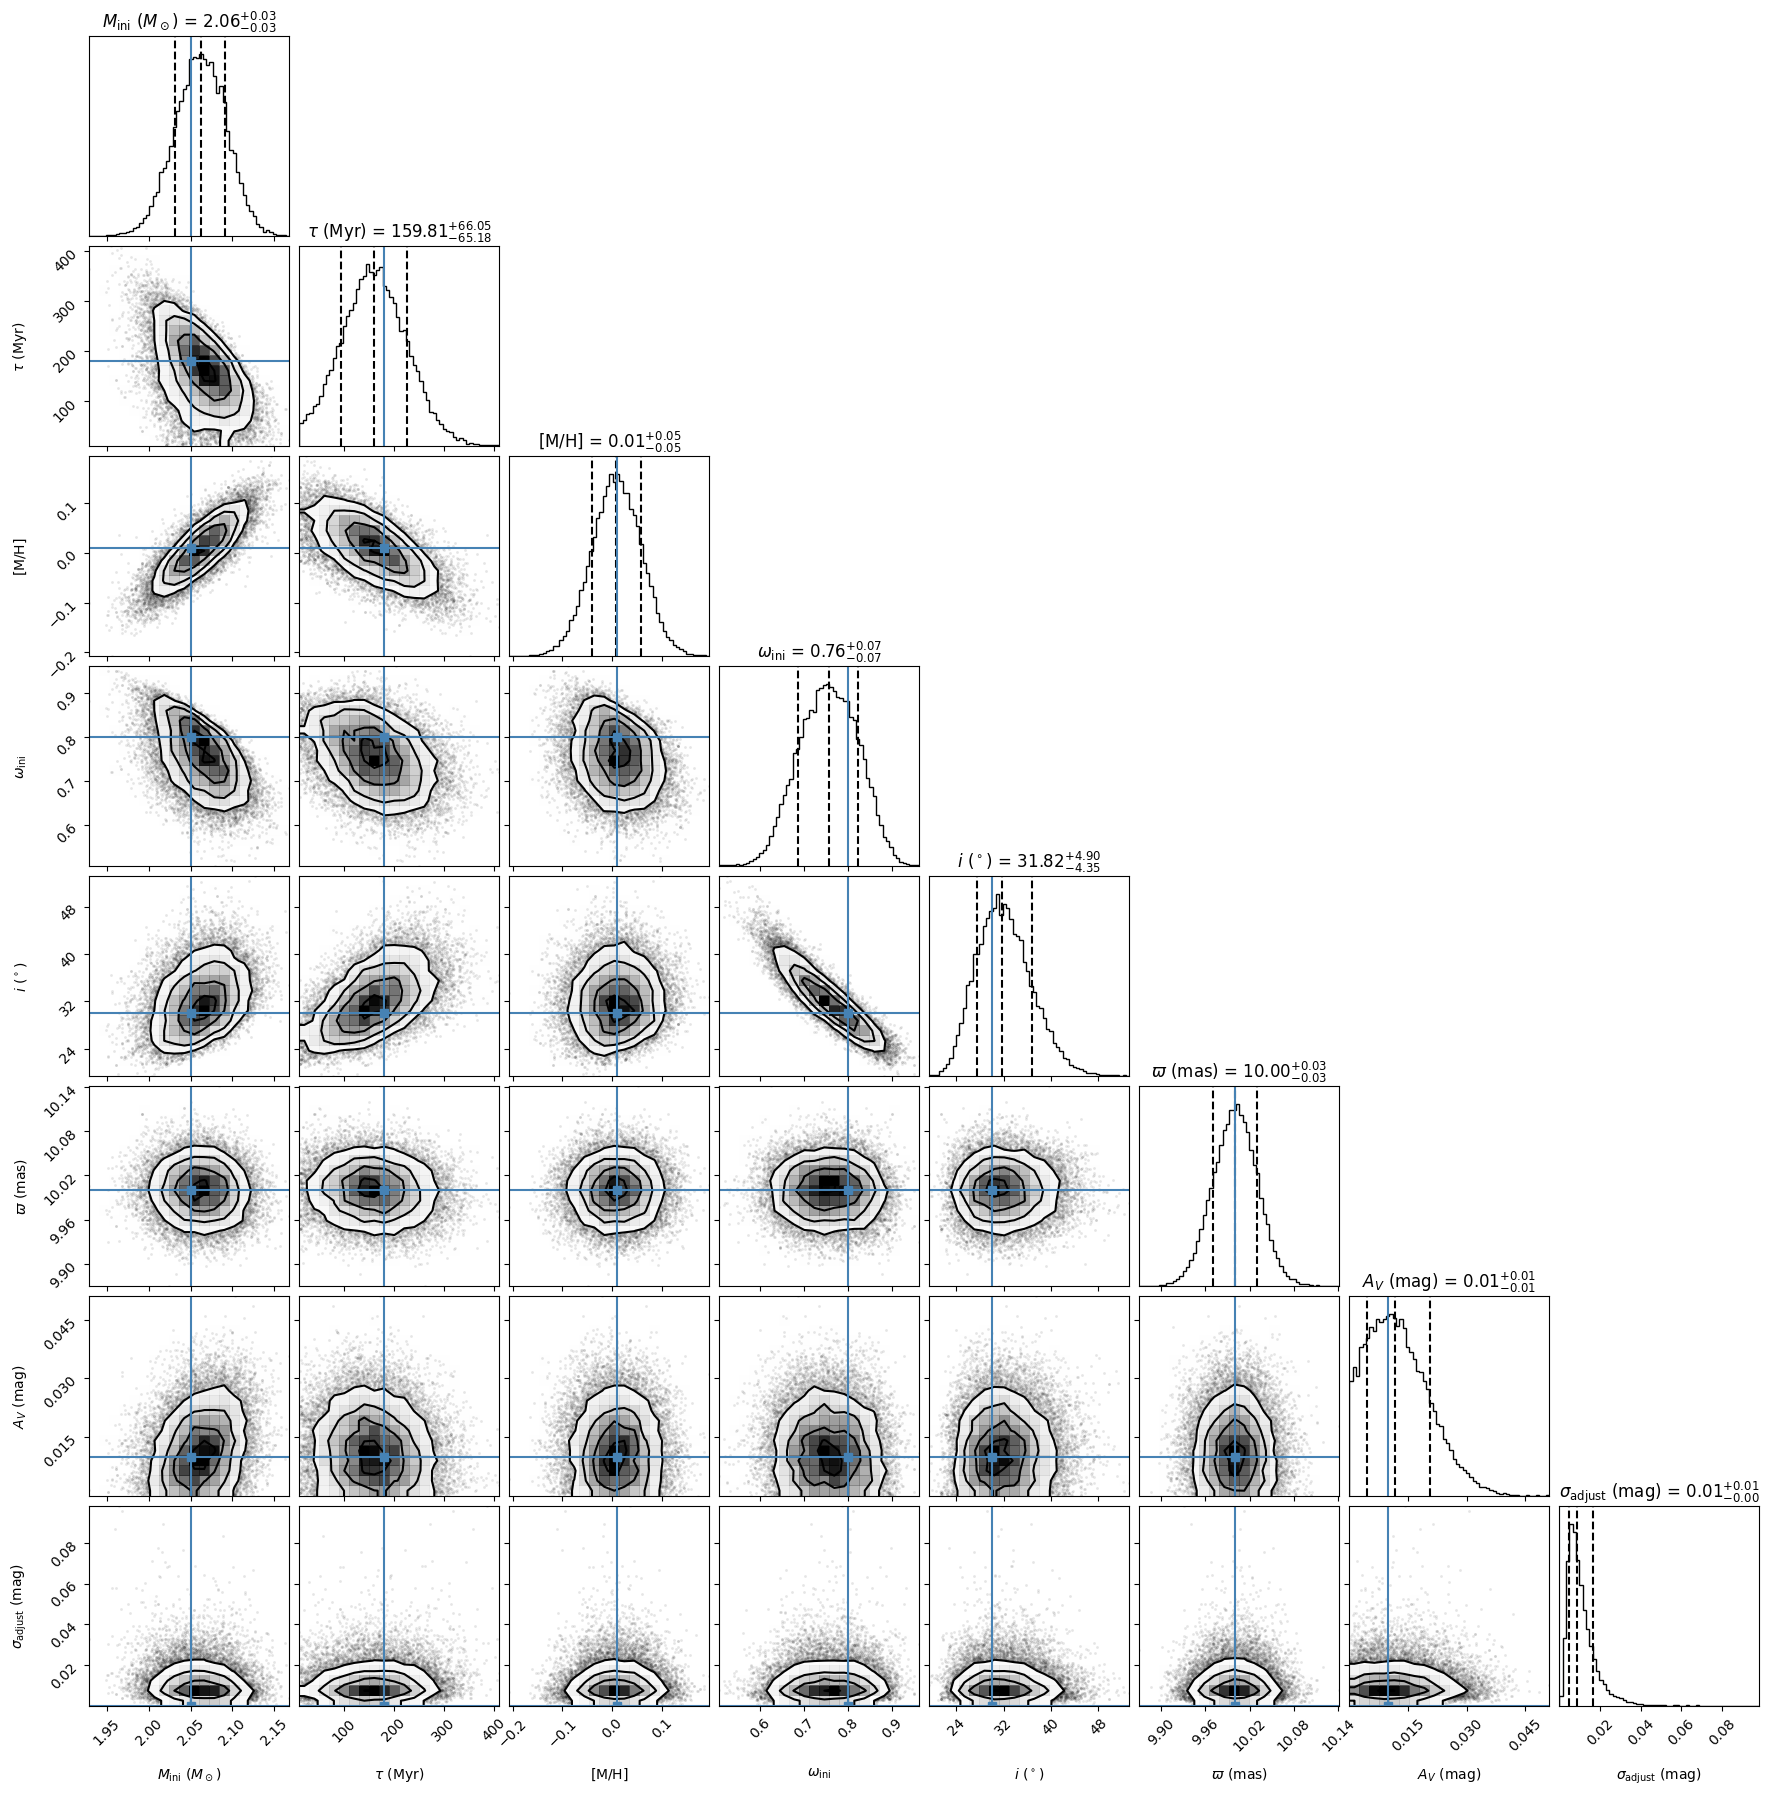

In [11]:
 # Save figures and samples, including corner plot, trace plots for all walkers, target file, and summary of results.

mcmc.target = target
target = mcmc.save_and_plot(
    sampler, plot_samples=20000,
    folder_suffix=f'A_V prior {extinction}±{extinction_err}; MH prior {true_values[2]}±0.05; inc prior {int(np.rad2deg(true_values[4]))}±6'
)

In [12]:
# check the SGB-contamination risk
target.check_risk()


## Posterior

Samples           (18144, 30, 6) | Blobs             (18144, 30, 21)
After discard      488,760 | Batch size           5,000

## Boundary grid

MH                -0.27561 -- 0.33637 | omega             0.300 -- 0.990
MH grid                N=6 | omega grid             N=6
Posterior Mini    1.929 -- 2.188 | Boundary Mini     1.629 -- 2.488
Mass grid             N=87 | Low-M extrap.         N=22


Classifying samples: 100%|██████████| 488760/488760 [00:11<00:00, 41740.96samples/s]


## Classification

Valid              488,760 | Invalid                  0
Safe               488,760 | Risky                    0
P(safe)            1.00000 | P(risky)           0.00000
